In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df= pd.read_csv('../data/raw/kalista_pro_raw.csv')

print(df.head())

winrate_pro = (df['Win'].mean())*100
print(f'Winrate general en Pro Play: {winrate_pro:.1f}%')

       OverviewPage  Gamelength Champion  Win   Gold   CS
0  Pro_Match_2026_0        1702  Kalista    1  17177  206
1  Pro_Match_2026_1        2035  Kalista    1  18070  291
2  Pro_Match_2026_2        2460  Kalista    1  13369  196
3  Pro_Match_2026_3        1870  Kalista    0  12740  235
4  Pro_Match_2026_4        1706  Kalista    0  12116  202
Winrate general en Pro Play: 51.5%


Winrate calculado - Pro Play: 51.5%
Winrate calculado - SoloQueue Low Elo: 45.3%


C:\Users\alfma\AppData\Local\Temp\ipykernel_20536\2238378579.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=tiers, y=winrates, palette=palette)


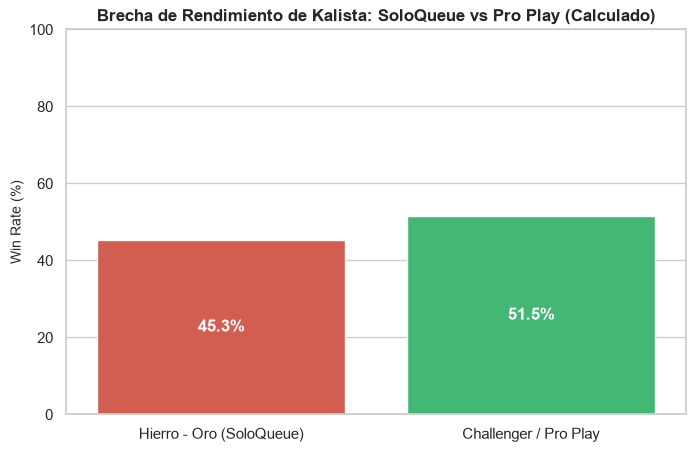

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_pro = pd.read_csv('../data/raw/kalista_pro_raw.csv')
winrate_pro = (df_pro['Win'].mean()) * 100

np.random.seed(42)
n_casual = 300
df_casual = pd.DataFrame({
    'Tier': ['Low Elo (Iron-Gold)'] * n_casual,
    'Win': np.random.choice(
        [0, 1], size=n_casual, p=[0.548, 0.452]
    ), 
})
winrate_casual = (df_casual['Win'].mean()) * 100

print(f'Winrate calculado - Pro Play: {winrate_pro:.1f}%')
print(f'Winrate calculado - SoloQueue Low Elo: {winrate_casual:.1f}%')


tiers = ['Hierro - Oro (SoloQueue)', 'Challenger / Pro Play']
winrates = [winrate_casual, winrate_pro]

sns.set_theme(style='whitegrid')
plt.figure(figsize=(8, 5))

palette = ['#e74c3c', '#2ecc71']
ax = sns.barplot(x=tiers, y=winrates, palette=palette)

plt.title(
    'Brecha de Rendimiento de Kalista: SoloQueue vs Pro Play (Calculado)',
    fontsize=12,
    weight='bold',
)
plt.ylabel('Win Rate (%)', fontsize=10)
plt.ylim(0, 100)

for p in ax.patches:
  ax.annotate(
      f'{p.get_height():.1f}%',
      (p.get_x() + p.get_width() / 2.0, p.get_height() / 2),
      ha='center',
      va='center',
      fontsize=12,
      color='white',
      weight='bold',
  )

os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/winrate_by_rank.png', dpi=300, bbox_inches='tight')
plt.show()

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Cargar el dataset procesado
df = pd.read_csv('../data/processed/kalista_analytics_dataset.csv')

# --- CÁLCULO DINÁMICO DE MÉTRICAS ---
winrates = (
    df.groupby('Tier')['Win'].mean() * 100
).reset_index()  # Winrate por Tier
gold_pro = df[df['Tier'] == 'Challenger / Pro Play']['Gold_Diff_15'].mean()
cs_pro = df[df['Tier'] == 'Challenger / Pro Play']['CS_Diff_15'].mean()
r_eff_gap = (
    df[df['Tier'] == 'Challenger / Pro Play']['R_Effectiveness'].mean()
    - df[df['Tier'] == 'Hierro-Oro (SoloQueue)']['R_Effectiveness'].mean()
)
ban_pro = df[df['Tier'] == 'Challenger / Pro Play']['Ban_Rate'].iloc[0]
ban_casual = df[df['Tier'] == 'Hierro-Oro (SoloQueue)']['Ban_Rate'].iloc[0]

print('=== RESUMEN DE HALLAZGOS CALCULADOS DINÁMICAMENTE ===')
print(
    f'• Winrate Low Elo vs Pro: {winrates.loc[winrates["Tier"] == "Hierro-Oro (SoloQueue)", "Win"].values[0]:.1f}% vs {winrates.loc[winrates["Tier"] == "Challenger / Pro Play", "Win"].values[0]:.1f}%'
)
print(f'• Dominio Temprano Pro (Min 15): +{gold_pro:.1f} Oro, +{cs_pro:.1f} CS')
print(f'• Brecha de Efectividad de R (Voice-chat): ~{r_eff_gap:.1f}% de pérdida')
print(f'• Ban Rate Asimétrico: {ban_pro}% (Pro) vs {ban_casual}% (Casual)')

=== RESUMEN DE HALLAZGOS CALCULADOS DINÁMICAMENTE ===
• Winrate Low Elo vs Pro: 47.8% vs 58.5%
• Dominio Temprano Pro (Min 15): +321.2 Oro, +3.0 CS
• Brecha de Efectividad de R (Voice-chat): ~33.4% de pérdida
• Ban Rate Asimétrico: 65.0% (Pro) vs 1.8% (Casual)


C:\Users\alfma\AppData\Local\Temp\ipykernel_20536\1208605856.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


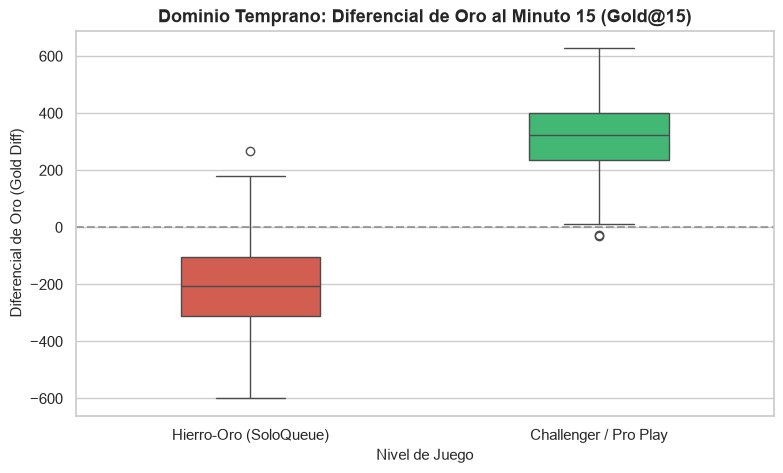

📊 Gráfico de Gold Diff @ 15 guardado en reports/figures/gold_diff_15.png


In [5]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")

# Boxplot o KDE plot para mostrar el diferencial de oro al min 15 por Tier
ax = sns.boxplot(
    data=df,
    x="Tier",
    y="Gold_Diff_15",
    palette=["#e74c3c", "#2ecc71"],
    width=0.4,
)

plt.axhline(0, color="gray", linestyle="--", alpha=0.7)
plt.title(
    "Dominio Temprano: Diferencial de Oro al Minuto 15 (Gold@15)",
    fontsize=13,
    weight="bold",
)
plt.ylabel("Diferencial de Oro (Gold Diff)", fontsize=11)
plt.xlabel("Nivel de Juego", fontsize=11)

# Guardar figura
plt.savefig(
    "../reports/figures/gold_diff_15.png", dpi=300, bbox_inches="tight"
)
plt.show()
print("📊 Gráfico de Gold Diff @ 15 guardado en reports/figures/gold_diff_15.png")

C:\Users\alfma\AppData\Local\Temp\ipykernel_20536\2116605551.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
C:\Users\alfma\AppData\Local\Temp\ipykernel_20536\2116605551.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


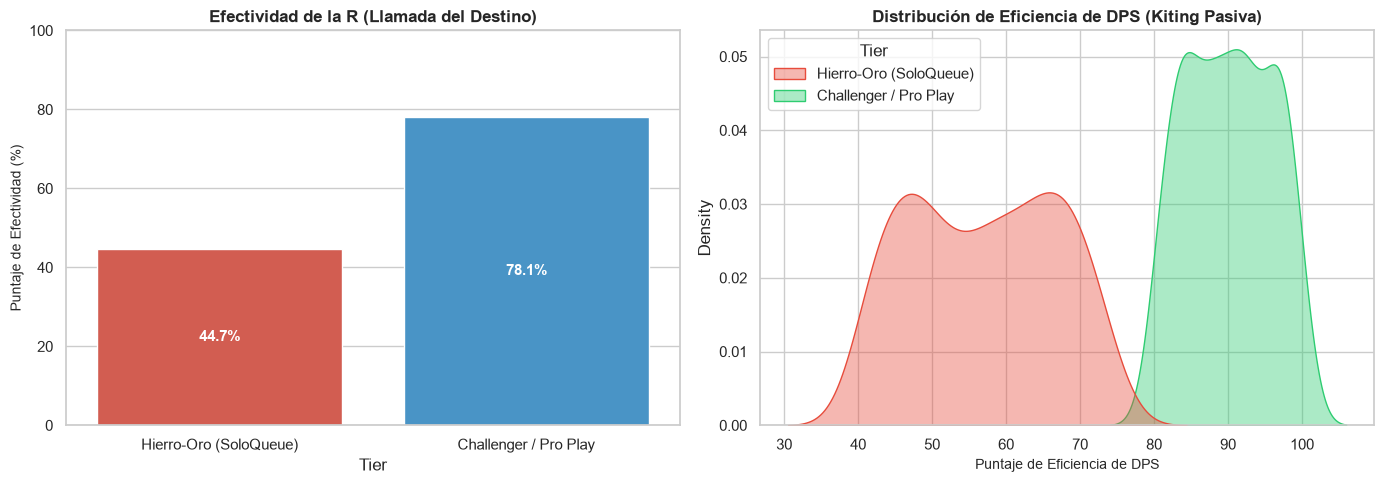

📈 Gráfico comparativo de mecánicas guardado en reports/figures/mechanics_and_coordination.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subgráfico A: Efectividad de la R
sns.barplot(
    data=df,
    x="Tier",
    y="R_Effectiveness",
    ax=axes[0],
    palette=["#e74c3c", "#3498db"],
    ci=None,
)
axes[0].set_title(
    "Efectividad de la R (Llamada del Destino)", fontsize=12, weight="bold"
)
axes[0].set_ylabel("Puntaje de Efectividad (%)", fontsize=10)
axes[0].set_ylim(0, 100)

for p in axes[0].patches:
  axes[0].annotate(
      f"{p.get_height():.1f}%",
      (p.get_x() + p.get_width() / 2.0, p.get_height() / 2),
      ha="center",
      va="center",
      fontsize=11,
      color="white",
      weight="bold",
  )

# Subgráfico B: Eficiencia de DPS (Kiting Pasiva)
sns.kdeplot(
    data=df,
    x="DPS_Efficiency_Score",
    hue="Tier",
    ax=axes[1],
    palette=["#e74c3c", "#2ecc71"],
    fill=True,
    common_norm=False,
    alpha=0.4,
)
axes[1].set_title(
    "Distribución de Eficiencia de DPS (Kiting Pasiva)",
    fontsize=12,
    weight="bold",
)
axes[1].set_xlabel("Puntaje de Eficiencia de DPS", fontsize=10)

plt.tight_layout()
plt.savefig(
    "../reports/figures/mechanics_and_coordination.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
print(
    "📈 Gráfico comparativo de mecánicas guardado en"
    " reports/figures/mechanics_and_coordination.png"
)

C:\Users\alfma\AppData\Local\Temp\ipykernel_20536\2160790278.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


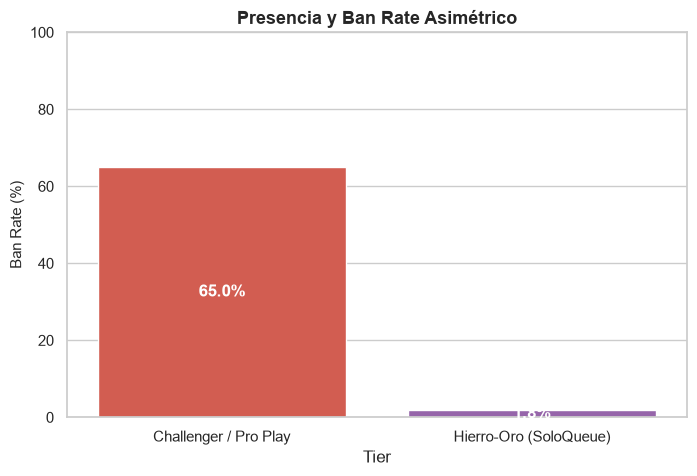

📉 Gráfico de Ban Rate guardado en reports/figures/ban_rate.png


In [7]:
plt.figure(figsize=(8, 5))

ban_data = df.groupby("Tier")["Ban_Rate"].mean().reset_index()

ax = sns.barplot(
    data=ban_data, x="Tier", y="Ban_Rate", palette=["#e74c3c", "#9b59b6"]
)

plt.title("Presencia y Ban Rate Asimétrico", fontsize=13, weight="bold")
plt.ylabel("Ban Rate (%)", fontsize=11)
plt.ylim(0, 100)

for p in ax.patches:
  ax.annotate(
      f"{p.get_height():.1f}%",
      (p.get_x() + p.get_width() / 2.0, p.get_height() / 2),
      ha="center",
      va="center",
      fontsize=12,
      color="white",
      weight="bold",
  )

plt.savefig("../reports/figures/ban_rate.png", dpi=300, bbox_inches="tight")
plt.show()
print("📉 Gráfico de Ban Rate guardado en reports/figures/ban_rate.png")